In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
adata=sc.read_h5ad('/home/julia/data/placodes/h5ad/E9_E10_E11_UMAP.h5ad')

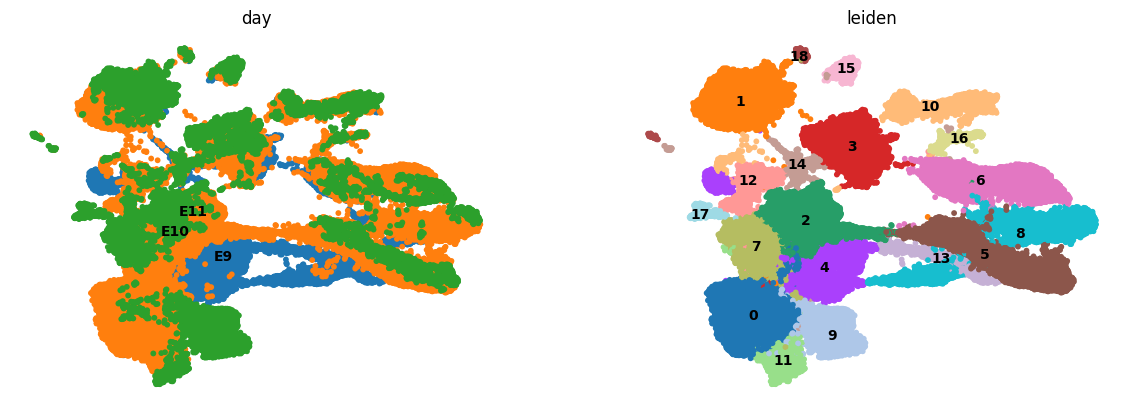

In [3]:
sc.pl.umap(adata, color=["day", "leiden"], layer="scaled", frameon=False, size=70, legend_loc='on data')

In [4]:
adata

AnnData object with n_obs × n_vars = 94890 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

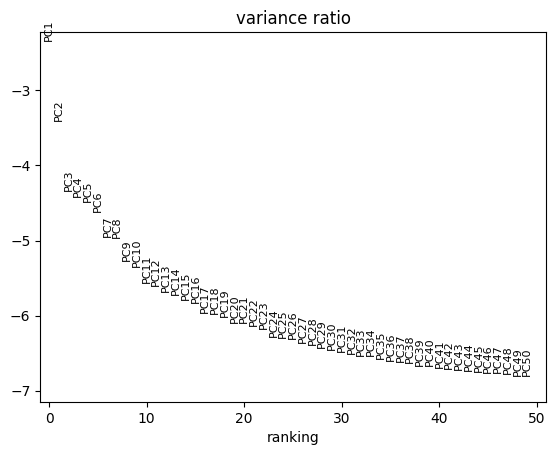

In [5]:
CLUSTERS = ["2", "5"]   # ← ваши кластеры
sub = adata[adata.obs["leiden"].isin(CLUSTERS)].copy()
sub.obs["leiden_parent"] = sub.obs["leiden"].astype(str)
#sc.pp.filter_genes(sub, min_cells=5)

sub.X = sub.layers["counts"].copy()
sc.pp.normalize_total(sub, target_sum=1e4)
sc.pp.log1p(sub)
sub.layers["lognorm"] = sub.X.copy()
sc.pp.highly_variable_genes(sub, flavor="seurat_v3", layer="counts", n_top_genes=2000)

# скейлинг + PCA во временной копии
tmp = sub[:, sub.var["highly_variable"]].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=50)
sc.pl.pca_variance_ratio(tmp, n_pcs=50, log=True)

sub.obsm["X_pca"] = tmp.obsm["X_pca"]
sub.uns["pca"] = tmp.uns["pca"]
del tmp

/tmp/ipykernel_2612748/1925106124.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(sub, resolution=0.8, key_added="leiden_sub")


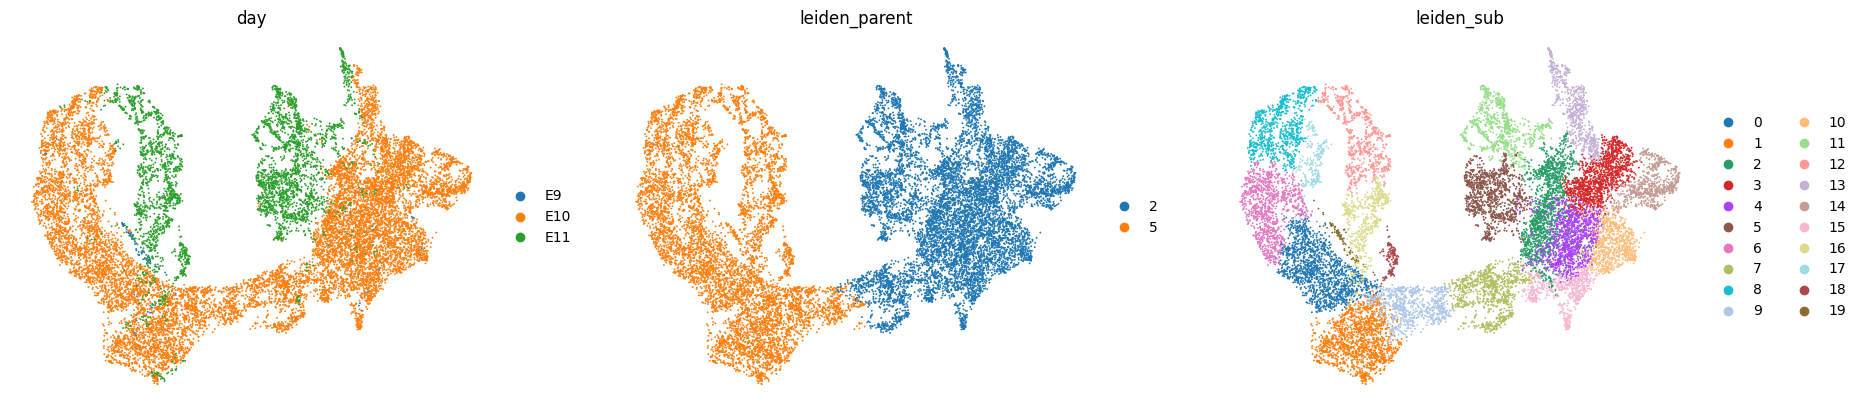

In [6]:
sc.pp.neighbors(sub, n_pcs=30, n_neighbors=35)   # n_pcs по графику локтя
sc.tl.leiden(sub, resolution=0.8, key_added="leiden_sub")
sc.tl.umap(sub)
sc.pl.umap(sub, color=["day", "leiden_parent", "leiden_sub"], frameon=False)

day
E10    12779
E11     3682
Name: count, dtype: int64


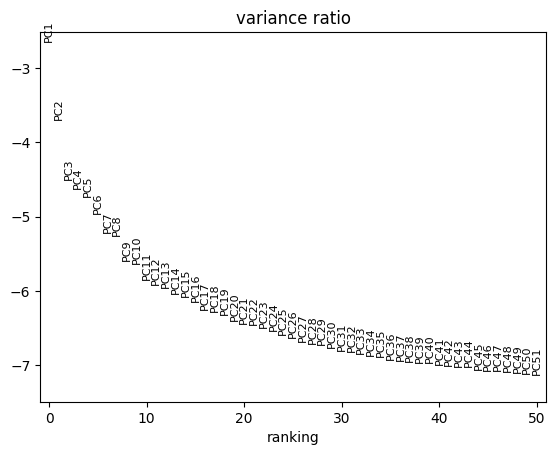

In [7]:
# just to try
# 1. убираем E9
sub1 = sub[sub.obs["day"] != "E9"].copy()
sub1.obs["day"] = sub1.obs["day"].cat.remove_unused_categories()
sub1.X = sub1.layers["lognorm"].copy()
print(sub1.obs["day"].value_counts())

# 2. HVG заново
sc.pp.highly_variable_genes(sub1, flavor="seurat_v3", layer="counts", n_top_genes=3500)
bad = sub1.var_names.str.startswith(("mt-", "Rps", "Rpl"))
sub1.var.loc[bad, "highly_variable"] = False

# 3. скейлинг + PCA во временной копии
tmp = sub1[:, sub1.var["highly_variable"]].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=80)
sc.pl.pca_variance_ratio(tmp, n_pcs=50, log=True)
sub1.obsm["X_pca"] = tmp.obsm["X_pca"]
sub1.uns["pca"] = tmp.uns["pca"]
del tmp

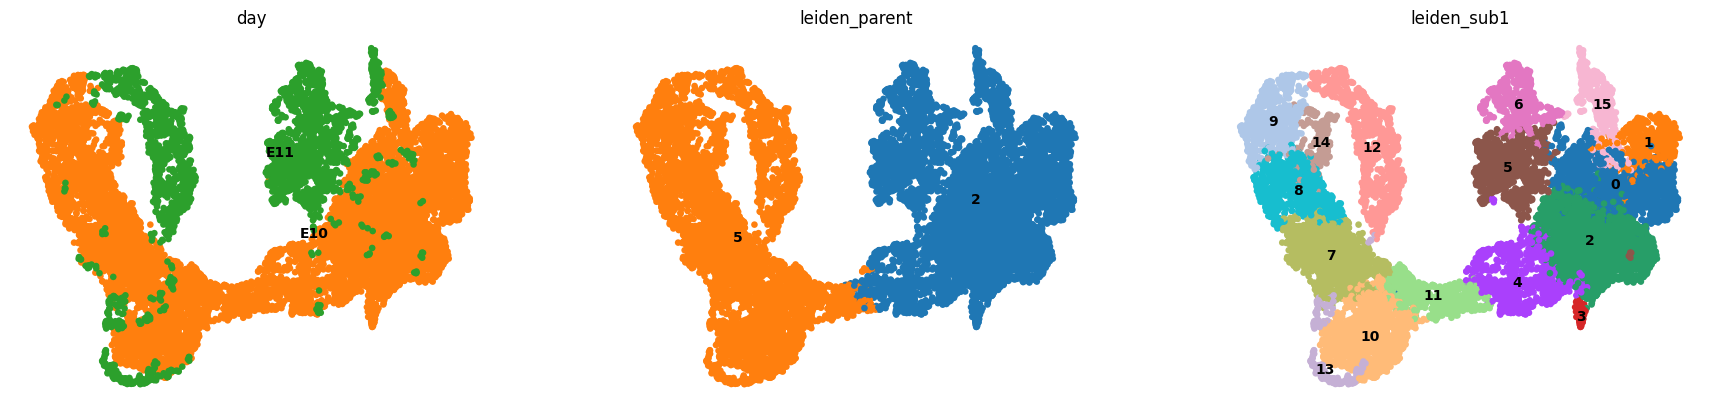

In [8]:
# 4. граф, кластеры, UMAP
sc.pp.neighbors(sub1, n_pcs=40, n_neighbors=40)
sc.tl.leiden(sub1, resolution=0.5, key_added="leiden_sub1",
             flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(sub1)
sc.pl.umap(sub1, color=["day", "leiden_parent", "leiden_sub1"],
           frameon=False, legend_loc="on data", size=90)

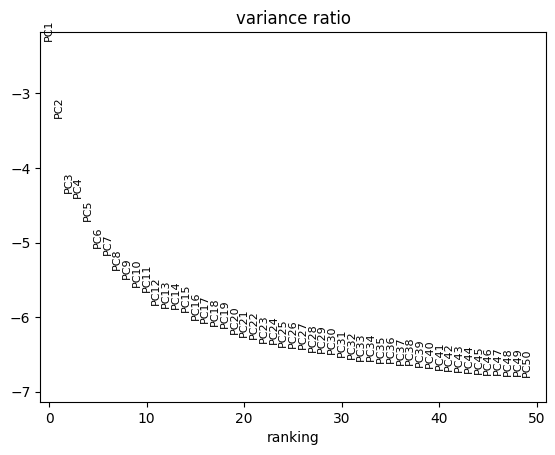

In [9]:
REMOVE = ["5", "6", "0","1", "15", "3"]          # ← какие подкластеры убрать
KEY = "leiden_sub1"      # ← по какой кластеризации

# 1. убираем клетки
sub2 = sub1[~sub1.obs[KEY].isin(REMOVE)].copy()
sub2.X = sub2.layers["lognorm"].copy()

# 2. HVG заново
sc.pp.highly_variable_genes(sub2, flavor="seurat_v3", layer="counts", n_top_genes=2000)

# 3. скейлинг + PCA во временной копии
tmp = sub2[:, sub2.var["highly_variable"]].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=50)
sc.pl.pca_variance_ratio(tmp, n_pcs=50, log=True)
sub2.obsm["X_pca"] = tmp.obsm["X_pca"]
sub2.uns["pca"] = tmp.uns["pca"]
del tmp



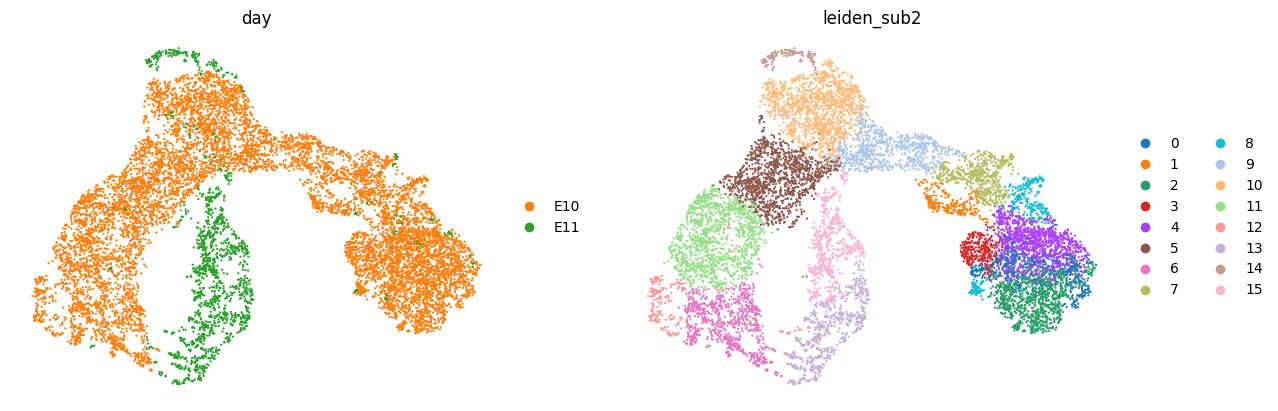

In [10]:
# 4. граф, кластеры, UMAP
sc.pp.neighbors(sub2, n_pcs=30, n_neighbors=30)
sc.tl.leiden(sub2, resolution=0.8, key_added="leiden_sub2",
             flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(sub2)
sc.pl.umap(sub2, color=["day", "leiden_sub2"], frameon=False)

In [11]:
sub.write_h5ad('epi_nodose.h5ad')